<div style="background:#E8F2F7;border-top:4px solid #7794BF;padding:12px 16px;color:#292722;font-family:monospace;font-size:12px;letter-spacing:0.06em;">
GEOSTATISTICS LESSONS · MULTIVARIATE STATISTICS · COMPANION NOTEBOOK
</div>

# Multidimensional Scaling

**Steven Mancell and Clayton Deutsch**

Notebook published: 2019

[Read the lesson](https://geostatisticslessons.com/lessons/mds) · [Notebook guide](README.md)

## Learning Objectives

- Appreciate high dimensional distance calculations with geological data
- Understand multidimensional scaling (MDS) within the framework of multivariate geostatistics.
- Interpret results from MDS to help understand multivariate data

## Overview

This notebook implements the Geostatistics Lesson <a href="https://geostatisticslessons.com/lessons/mds">Multidimensional Scaling</a>. This code is provided for educational purposes and should be reviewed jointly with the lesson.


These examples are strictly for educational purposes and should not be misconstrued as financial or professional advice.

In [1]:
import platform
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import preprocessing
from sklearn.manifold import MDS
from sklearn.metrics import pairwise_distances

%matplotlib inline

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "text.color": "#292722",
        "axes.labelcolor": "#292722",
        "axes.edgecolor": "#292722",
        "font.size": 11,
    }
)

# Start the kernel from the repository root, alongside the data/ folder.
DATA_DIR = Path.cwd() / "data"
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        "Start this notebook from the repository root, which contains data/."
    )

print(f"Python {platform.python_version()}")
print(
    " · ".join(
        f"{name} {version(name)}"
        for name in ["numpy", "pandas", "matplotlib", "scipy", "scikit-learn"]
    )
)

Python 3.12.7
numpy 1.26.4 · pandas 2.1.4 · matplotlib 3.9.2 · scipy 1.14.1 · scikit-learn 1.5.2


## Load Reported 2017 Mining Company Data

In [2]:
df = pd.read_csv(DATA_DIR / "mds_mining_company_data.csv")
df.rename(columns=dict([(col, col.strip()) for col in df.columns]), inplace=True)
df.describe()

,Share Price,Earnings,Earnings/Share,Cashflow,Market Cap,Gold Production,AISC,Cash Cost,Reserve,Grade,Revenue,Shares Out
count,14.000000,14.000000,14.000000,14.000000,14.000000,14.000000,14.000000,14.000000,14.000000,14.000000,14.000000,14.000000
mean,6.395000,180.421429,0.006429,126.100000,1843.542857,488.071429,873.714286,614.357143,9.390000,3.415714,612.578571,371.664286
std,4.127575,187.294746,0.645405,168.905413,832.543666,238.081907,126.420804,143.650541,5.311555,4.373785,307.069815,235.714605
min,2.380000,-108.000000,-1.730000,-172.200000,678.600000,145.000000,617.000000,347.000000,2.700000,0.700000,178.000000,120.000000
25%,2.987500,28.225000,-0.005000,44.450000,1099.275000,312.250000,822.000000,517.250000,4.920000,1.215000,405.800000,189.675000
50%,5.610000,173.750000,0.060000,106.500000,1761.750000,501.000000,898.500000,635.000000,8.075000,1.460000,656.200000,309.000000
75%,8.505000,253.250000,0.325000,279.000000,2431.050000,621.500000,958.750000,712.750000,14.650000,3.227500,745.375000,452.450000
max,15.360000,501.600000,0.720000,357.600000,3220.400000,882.000000,1064.000000,835.000000,17.300000,15.500000,1200.000000,990.000000


### Standardize and Scale the Data

In [3]:
companies = df["Ticker"].tolist()
print("Companies:", ", ".join(companies))
df.drop(columns=["Ticker"], inplace=True)

variables = df.columns.tolist()
print("Variables:", ", ".join(variables))

Companies: ACA, AGI, BTG, CG, DGC, EGO, IAG, KL, LMC, NGD, OGC, PVG, SMF, SSRM
Variables: Share Price, Earnings, Earnings/Share, Cashflow, Market Cap, Gold Production, AISC, Cash Cost, Reserve, Grade, Revenue, Shares Out


In [4]:
# Standardize to zero mean and unit variance
std_scaler = preprocessing.StandardScaler()
df = pd.DataFrame(std_scaler.fit_transform(df), columns=df.columns, index=df.index)
df.describe()

,Share Price,Earnings,Earnings/Share,Cashflow,Market Cap,Gold Production,AISC,Cash Cost,Reserve,Grade,Revenue,Shares Out
count,1.400000e+01,1.400000e+01,1.400000e+01,1.400000e+01,1.400000e+01,1.400000e+01,1.400000e+01,1.400000e+01,1.400000e+01,1.400000e+01,1.400000e+01,1.400000e+01
mean,-7.930164e-17,-1.189525e-17,-7.930164e-17,3.172066e-17,1.665335e-16,4.758099e-17,3.806479e-16,-1.982541e-16,-1.268826e-16,-5.551115e-17,-2.379049e-17,1.586033e-17
std,1.037749e+00,1.037749e+00,1.037749e+00,1.037749e+00,1.037749e+00,1.037749e+00,1.037749e+00,1.037749e+00,1.037749e+00,1.037749e+00,1.037749e+00,1.037749e+00
min,-1.009446e+00,-1.598064e+00,-2.792009e+00,-1.832745e+00,-1.452078e+00,-1.495376e+00,-2.107288e+00,-1.931421e+00,-1.307064e+00,-6.443458e-01,-1.468668e+00,-1.107969e+00
25%,-8.567089e-01,-8.432789e-01,-1.837604e-02,-5.016548e-01,-9.277150e-01,-7.663687e-01,-4.245065e-01,-7.015139e-01,-8.733296e-01,-5.221540e-01,-6.988126e-01,-8.012198e-01
50%,-1.973636e-01,-3.696456e-02,8.613768e-02,-1.204217e-01,-1.019532e-01,5.635293e-02,2.034582e-01,1.491265e-01,-2.569191e-01,-4.640239e-01,1.474196e-01,-2.758836e-01
75%,5.304932e-01,4.035232e-01,5.122320e-01,9.394123e-01,7.323159e-01,5.815871e-01,6.980317e-01,7.108020e-01,1.027676e+00,-4.465679e-02,4.487884e-01,3.556644e-01
max,2.253968e+00,1.779563e+00,1.147354e+00,1.422328e+00,1.716225e+00,1.717052e+00,1.561996e+00,1.593951e+00,1.545422e+00,2.867186e+00,1.985203e+00,2.722264e+00


## Correlation Matrix of Rescaled Variables

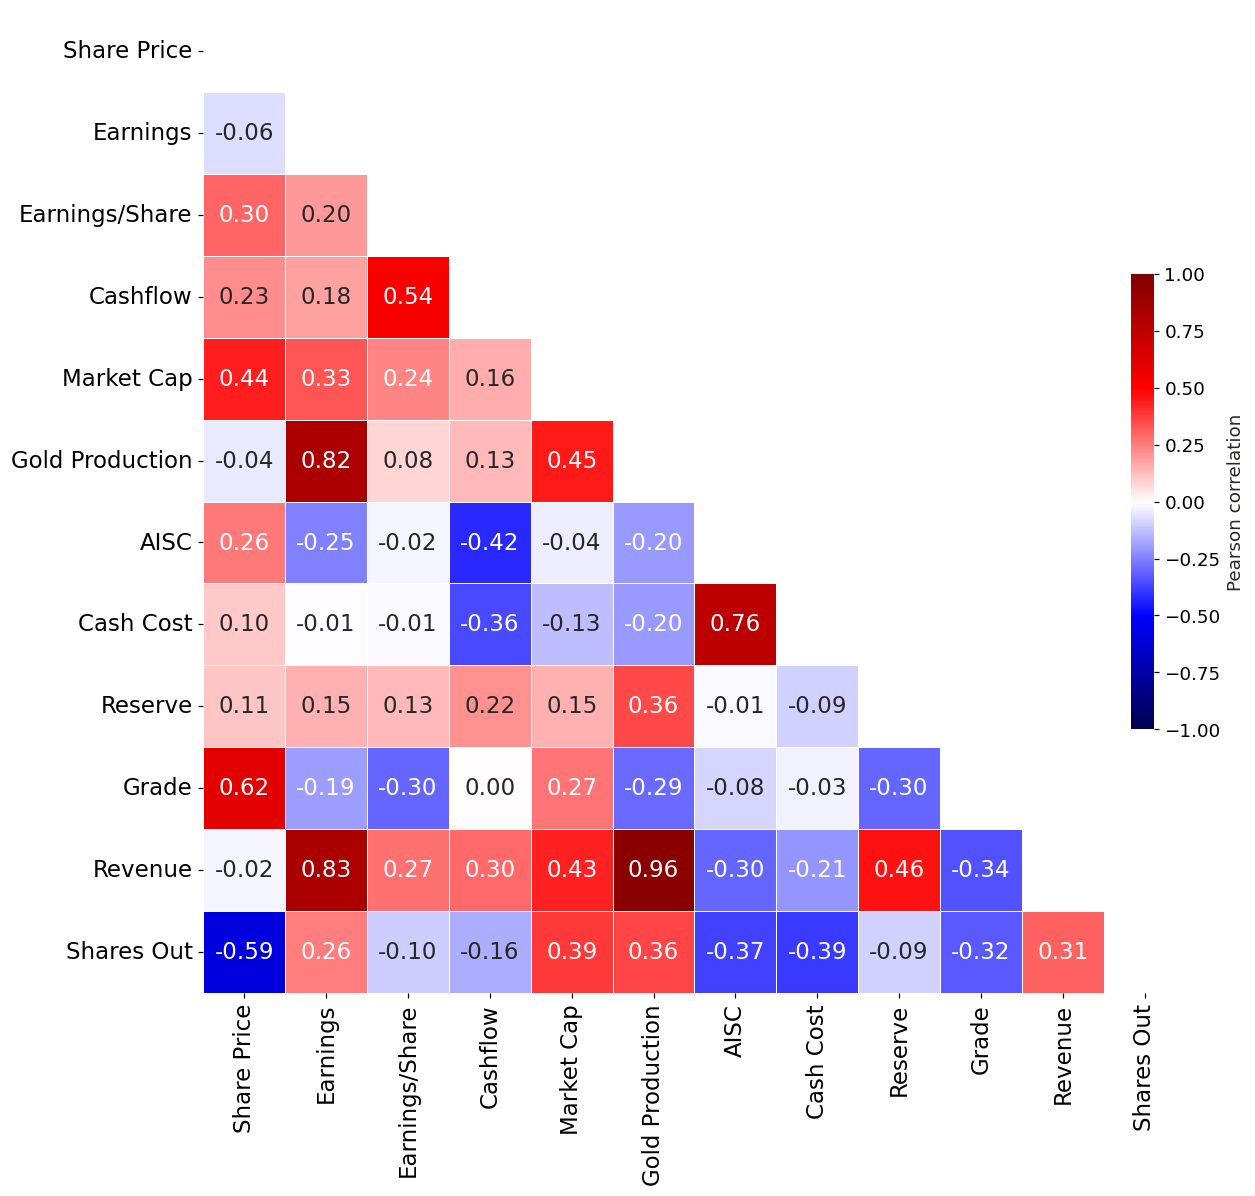

In [5]:
# Calculate correlation matrix
corrmat = df.corr()

# Set up the matplotlib figure
f, ax = plt.subplots(figsize=(12, 12))
ax = sns.heatmap(
    corrmat,
    mask=np.triu(np.ones(corrmat.shape)).astype(bool),
    cmap="seismic",
    vmin=-1,
    vmax=1,
    annot=True,
    annot_kws={"size": 15.0},
    fmt=".2f",
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.4, "pad": -0.05},
)

# Colorbar
cbar = ax.collections[0].colorbar
cbar.set_label(label="Pearson correlation", size=12)
cbar.ax.tick_params(labelsize=12)
cbar.solids.set_edgecolor("face")

# Ticks
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tick_params(axis="both", labelsize=15)
plt.tight_layout()

plt.show()

## Multidimensional Scaling (MDS)

### 1) Using 1 - Correlation as Distance for MDS

In [6]:
# Distance matrix
corr_dmatrix = 1 - corrmat

model = MDS(
    n_components=3,
    dissimilarity="precomputed",
    random_state=1,
    n_init=4,
    max_iter=300,
    eps=1e-3,
    normalized_stress=False,
)
mds_out = model.fit_transform(corr_dmatrix)

x = mds_out[:, 0]
y = mds_out[:, 1]
z = mds_out[:, 2]

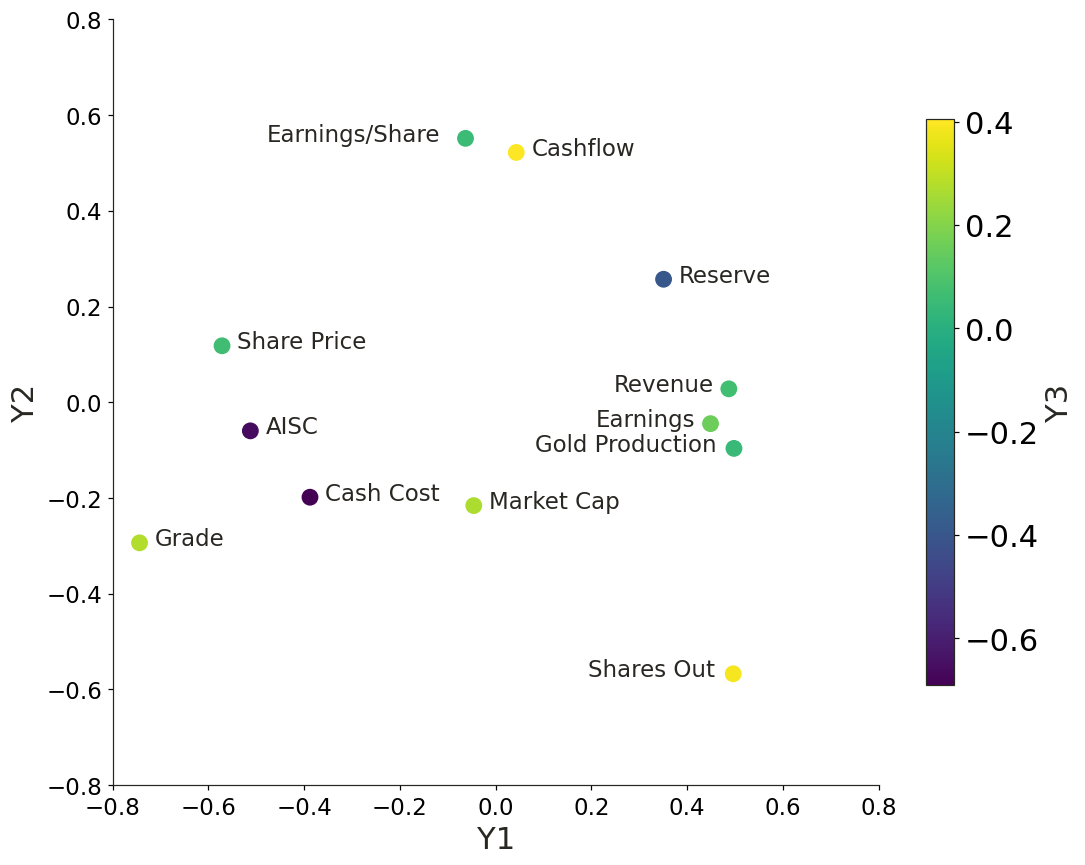

In [7]:
# MDS plot of variables as entities
fig, ax = plt.subplots(figsize=(10, 8))
ax.set_aspect("equal")
plot = ax.scatter(x, y, s=100, c=z)

# Shift conflicting labels
for i, txt in enumerate(variables):
    if txt == "Revenue" or txt == "Earnings":
        ax.annotate(
            txt,
            xy=(x[i], y[i]),
            xytext=(-75, 10),
            fontsize=15,
            va="top",
            xycoords="data",
            textcoords="offset points",
        )
    elif txt == "Shares Out":
        ax.annotate(
            txt,
            xy=(x[i], y[i]),
            xytext=(-95, 10),
            fontsize=15,
            va="top",
            xycoords="data",
            textcoords="offset points",
        )
    elif txt == "Gold Production" or txt == "Earnings/Share":
        ax.annotate(
            txt,
            xy=(x[i], y[i]),
            xytext=(-130, 10),
            fontsize=15,
            va="top",
            xycoords="data",
            textcoords="offset points",
        )
    else:
        ax.annotate(
            txt,
            xy=(x[i], y[i]),
            xytext=(10, 10),
            fontsize=15,
            va="top",
            xycoords="data",
            textcoords="offset points",
        )

# Colorbar
cbar = fig.colorbar(plot, pad=0.05, fraction=0.03)
cbar.solids.set_edgecolor("face")
cbar.set_label(label="Y3", size=20)
cbar.ax.tick_params(labelsize=20)

# Ticks and labels
ax.set_xlabel("Y1", fontsize=20)
ax.set_ylabel("Y2", fontsize=20)
ax.set_xlim((-0.8, 0.8))
ax.set_ylim((-0.8, 0.8))
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tick_params(axis="both", labelsize=15)
plt.tight_layout()

plt.show()

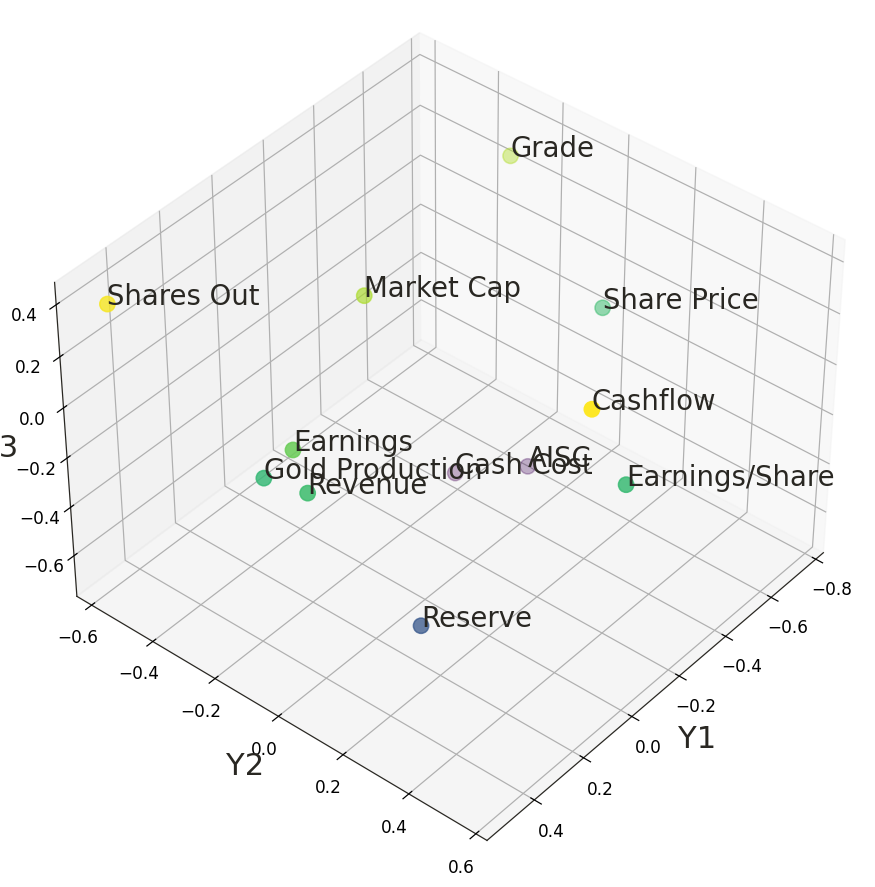

In [8]:
# Oblique view
fig = plt.figure(figsize=(10, 10))
ax = plt.axes(projection="3d")

ax.scatter3D(x, y, z, s=100, c=z)

ax.view_init(azim=40, elev=40)
ax.set_xlabel("Y1", fontsize=20)
ax.set_ylabel("Y2", fontsize=20)
ax.set_zlabel("Y3", fontsize=20)

for i, txt in enumerate(variables):
    ax.text(x[i], y[i], z[i], txt, fontsize=18)

plt.show()

### 2) Using Euclidean Distance for MDS

In [9]:
euc_dist = pairwise_distances(df)

euc_model = MDS(
    n_components=3,
    dissimilarity="precomputed",
    random_state=1,
    n_init=4,
    max_iter=300,
    eps=1e-3,
    normalized_stress=False,
)
euc_mod_out = euc_model.fit_transform(euc_dist)

x = euc_mod_out[:, 0]
y = euc_mod_out[:, 1]
z = euc_mod_out[:, 2]

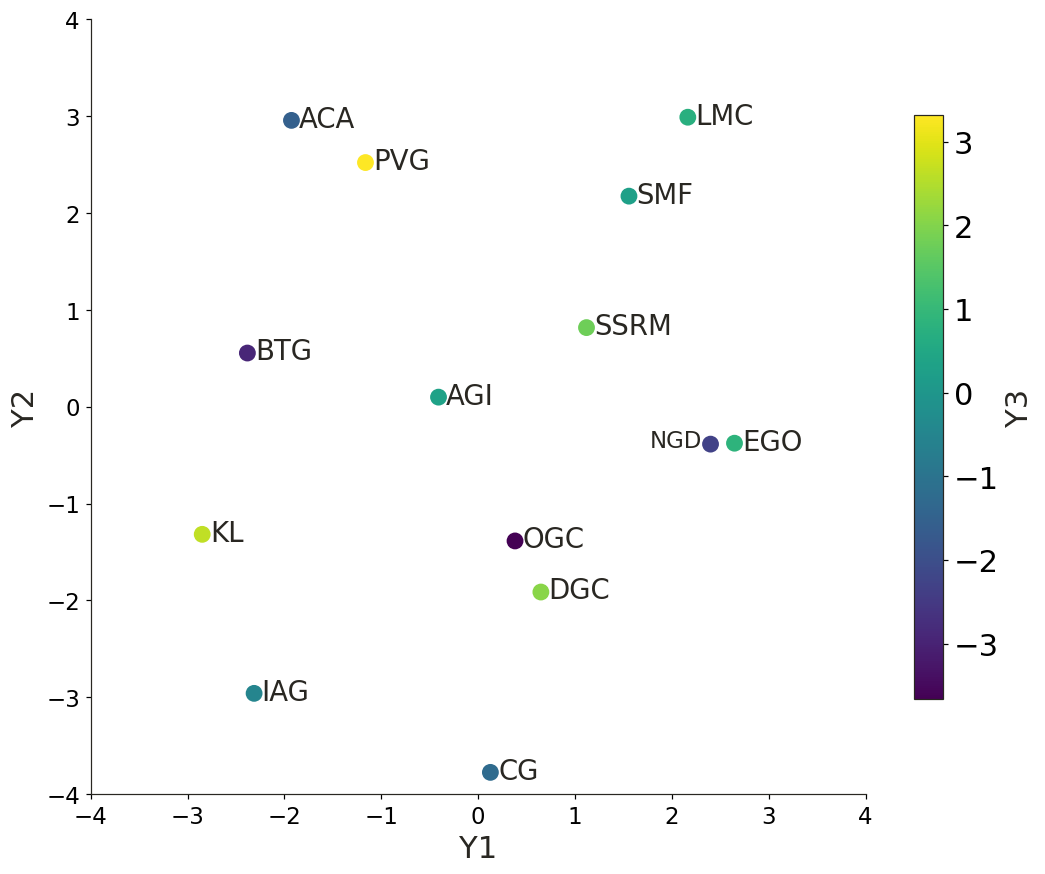

In [10]:
# Plot of MDS for companies
fig, ax = plt.subplots(figsize=(10, 8))
ax.set_aspect("equal")
plot = ax.scatter(x, y, s=100, c=z)

for i, txt in enumerate(companies):
    if txt == "NGD":
        ax.annotate(
            txt,
            xy=(x[i], y[i]),
            xytext=(-40, 10),
            fontsize=15,
            va="top",
            xycoords="data",
            textcoords="offset points",
        )
    else:
        ax.annotate(
            txt,
            (x[i], y[i]),
            xytext=(5, 10),
            fontsize=18,
            va="top",
            xycoords="data",
            textcoords="offset points",
        )

cbar = fig.colorbar(plot, pad=0.05, fraction=0.03)
cbar.solids.set_edgecolor("face")
cbar.set_label(label="Y3", size=20)
cbar.ax.tick_params(labelsize=20)

ax.set_xlabel("Y1", fontsize=20)
ax.set_ylabel("Y2", fontsize=20)
plt.tick_params(axis="both", labelsize=15)
plt.tight_layout()

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlim((-4, 4))
ax.set_ylim((-4, 4))

plt.show()

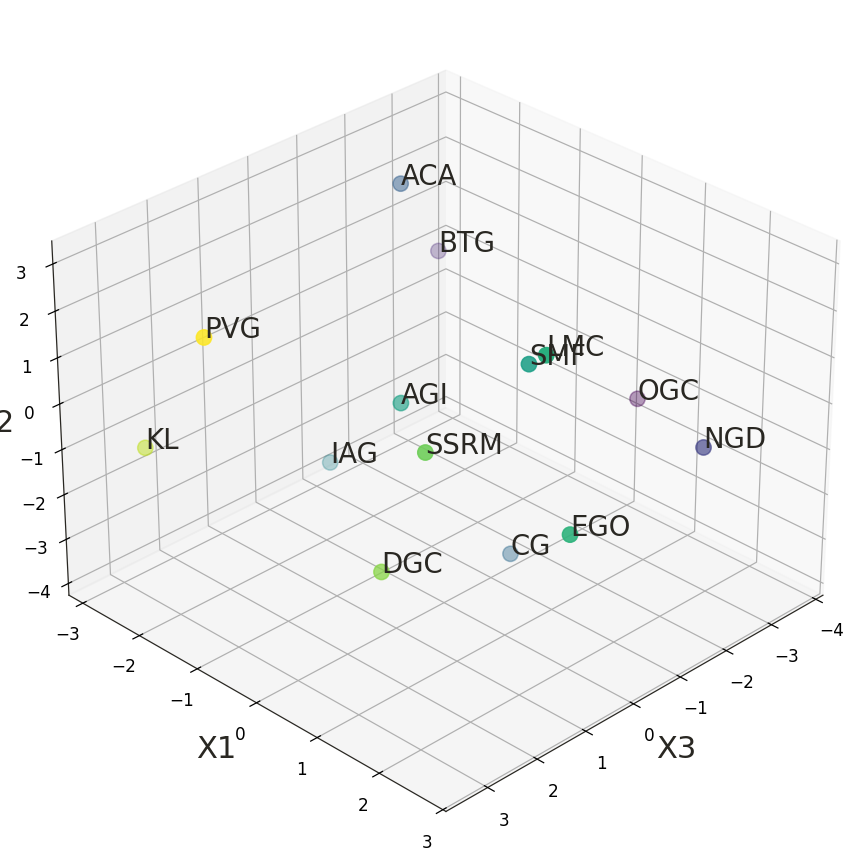

In [11]:
# 3-D View
fig = plt.figure(figsize=(10, 10))
ax = plt.axes(projection="3d")

ax.scatter3D(z, x, y, s=100, c=z)

ax.view_init(azim=45, elev=30)
ax.set_xlabel("X3", fontsize=20)
ax.set_ylabel("X1", fontsize=20)
ax.set_zlabel("X2", fontsize=20)
for i, txt in enumerate(companies):
    ax.text(z[i], x[i], y[i], txt, fontsize=18)

plt.show()